<a href="https://colab.research.google.com/github/JaquelinedeJesus/Simulaci-n-2/blob/main/M%C3%A9todo%20de%20Metropolis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Simulación mediante el algoritmo de Metrópolis-Hastings**

**Alumna:** Jaqueline de Jesús Espinoza Cano

## **Objetivo:**

Reproducir a través de simulaciones el algoritmo de Metropolis-Hastings con el fin de obtener muestras de una distribución de probabilidad bidimensional definida por una función objetivo
$f(x_1, x_2)$.

Se pretende examinar cómo se comportan y convergen distintas cadenas de Markov que parten de puntos iniciales variados. Asimismo, se busca validar gráficamente que las muestras generadas tienden a agruparse en las zonas de mayor densidad de la función objetivo. Para lograr esto, se emplearán herramientas visuales como gráficos de las cadenas, mapas de calor de la función y la representación de las muestras resultantes de la simulación.

## **Ejercicio:**

Simular mediante el algoritmo de Metropolis-Hastings una distribución de probabilidad bidimensional cuya función de densidad es proporcional a:

$f(x_1,x_2)=Cexp[-\frac{x_1^2x_2^2+x_1^2+x_2^2-8x_1-8x_2}{2}]$

Para la simulación se utilizaremos una distribución propuesta normal, quesu probabilidad de aceptación se puede expresar como:

$\alpha(X,Y)$=$min$ {$\ 1,\frac{\pi(Y)}{\pi(Y)}$}

## **Método**



1.   Se selecciona una posición de partida arbitraria denotada como $X_0=(x_1,x_2)$
2.    Se obtiene un valor tentativo $Y$ tomando como base una distribución normal:
$Y \sim N(X_t, \sigma^2 I)$

3. Se determina la probabilidad de aceptar el nuevo valor mediante la fórmula:

$\alpha(X_t, Y)$ = $\min$ {$\ 1, $ $\frac{\pi(Y)}{\pi(X_t)}$}

4. Se extrae un número al azar con distribución uniforme:

$U \sim U(0, 1)$

5. Si se cumple la condición:

$U \leq \alpha(X_t, Y)$

entonces el candidato es aceptado y el estado avanza:

$X_t$$_+$$_1$ $=Y$

De lo contrario, el sistema se mantiene sin cambios en la posición actual:

$X_t$$_+$$_1$ $=X_t$

6. Este ciclo se repite una cantidad determinada de iteraciones.

Finalmente, el conjunto de datos recolectados conforma una cadena de Markov, cuya distribución límite o estacionaria converge hacia la distribución objetivo deseada.


In [28]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as st


# DEFINICIÓN DE LA FUNCIÓN OBJETIVO (DENSIDAD)

def target(x):

    x1 = x[0]
    x2 = x[1]

    return np.exp(
        -(x1**2 * x2**2 + x1**2 + x2**2 - 8*x1 - 8*x2) / 2
    )


# IMPLEMENTACIÓN DEL ALGORITMO METROPOLIS-HASTINGS

def metropolissampler(niters, x0, sigma):

    # Almacenar las coordenadas x1 y x2 de la trayectoria
    samples = np.zeros((niters + 1, 2))

    # Estado inicial de la cadena
    x = np.array(x0, dtype=float)

    samples[0] = x

    aceptadas = 0

    for i in range(niters):

        # Primer paso: proponer valor tentativo
        # Y ~ N(Xt, sigma^2)

        x_p = x + np.random.normal(0, sigma, 2)

        # Segundo paso: evaluar el criterio de aceptación

        fx = target(x)
        fx_p = target(x_p)

        alpha = min(1, fx_p / fx)

        # Tercer paso: generar un número aleatorio U ~ Uniforme(0,1)

        u = np.random.uniform()

        # Cuarto paso: se acepta o se rechaza la propuesta

        if u < alpha:
            x = x_p
            aceptadas += 1

        # Guardar el estado actual de la cadena
        samples[i + 1] = x

    tasa_aceptacion = aceptadas / niters

    return samples, tasa_aceptacion


# EJECUCIÓN DE LA SIMULACIÓN

niters = 50000
sigma = 0.5

# Conjunto de estados de partida
puntos_iniciales = [
    [0.01, 0.01],
    [0.3, 0.3],
    [0.5, 0.5]
]

cadenas = []

for punto in puntos_iniciales:

    cadena, tasa = metropolissampler(
        niters,
        punto,
        sigma
    )

    cadenas.append(cadena)

    print(
        "Estado inicial:", punto,
        " | Tasa de aceptación:", round(tasa, 4)
    )

Estado inicial: [0.01, 0.01]  | Tasa de aceptación: 0.5177
Estado inicial: [0.3, 0.3]  | Tasa de aceptación: 0.5131
Estado inicial: [0.5, 0.5]  | Tasa de aceptación: 0.5225


# **Gráfica de las cadenas de Markov**

<>:15: SyntaxWarning: invalid escape sequence '\('
<>:33: SyntaxWarning: invalid escape sequence '\('
<>:15: SyntaxWarning: invalid escape sequence '\('
<>:33: SyntaxWarning: invalid escape sequence '\('
/tmp/ipykernel_1139/214563373.py:15: SyntaxWarning: invalid escape sequence '\('
  plt.ylabel("Variable \(x_1\)")
/tmp/ipykernel_1139/214563373.py:33: SyntaxWarning: invalid escape sequence '\('
  plt.ylabel("Variable \(x_2\)")


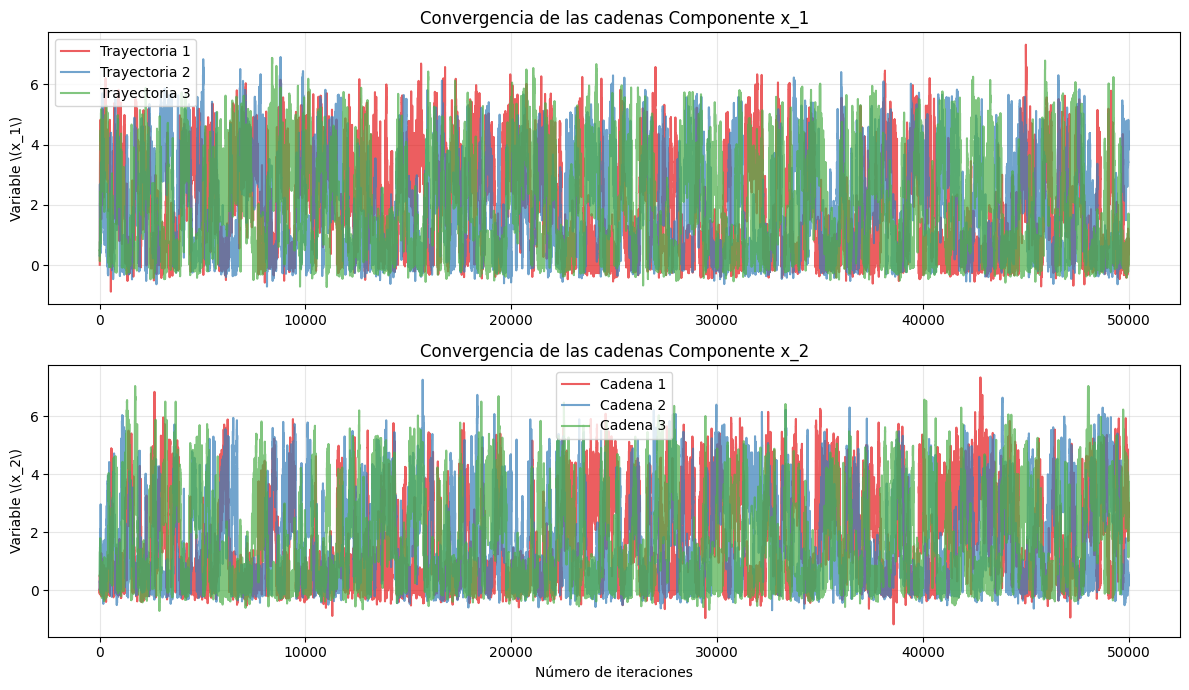

In [12]:
plt.figure(figsize=(12, 7))

colores = ['#e41a1c', '#377eb8', '#4daf4a']

for i in range(len(cadenas)):

    plt.subplot(2, 1, 1)
    plt.plot(
        cadenas[i][:, 0],
        alpha=0.7,
        color=colores[i],
        label="Trayectoria " + str(i + 1)
    )

plt.ylabel("Variable \(x_1\)")
plt.title("Convergencia de las cadenas Componente x_1")
plt.legend()
plt.grid(alpha=0.3)


plt.subplot(2, 1, 2)

for i in range(len(cadenas)):

    plt.plot(
        cadenas[i][:, 1],
        alpha=0.7,
        color=colores[i],
        label="Cadena " + str(i + 1)
    )

plt.xlabel("Número de iteraciones")
plt.ylabel("Variable \(x_2\)")
plt.title("Convergencia de las cadenas Componente x_2")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# **Mapa de calor de la función objetivo y gráfica 3D**

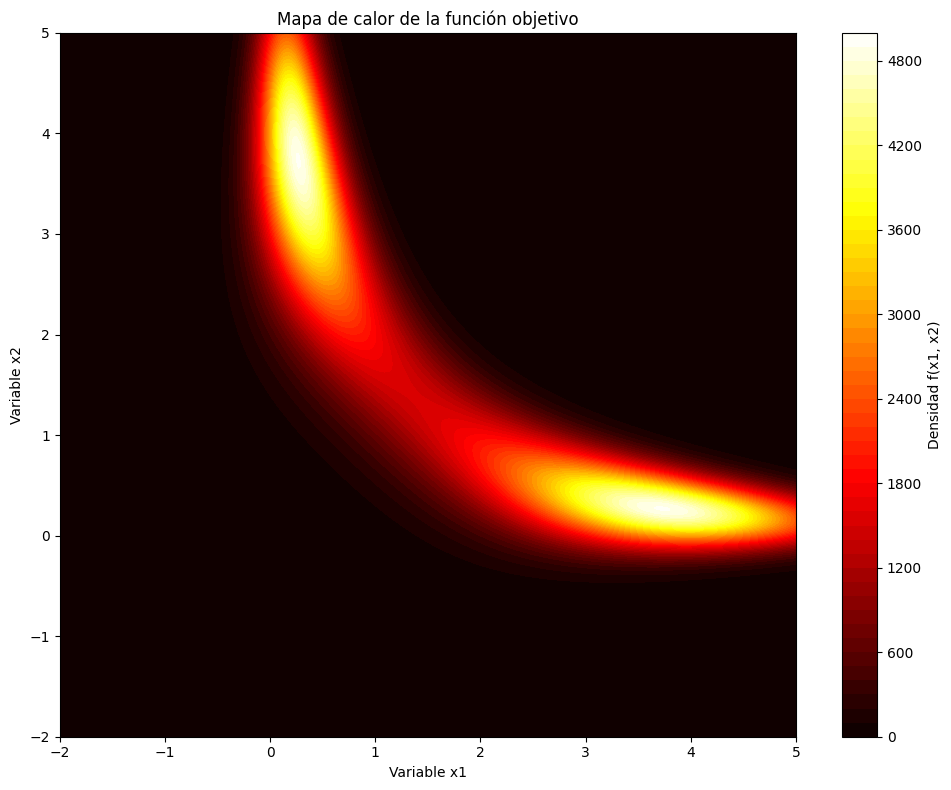

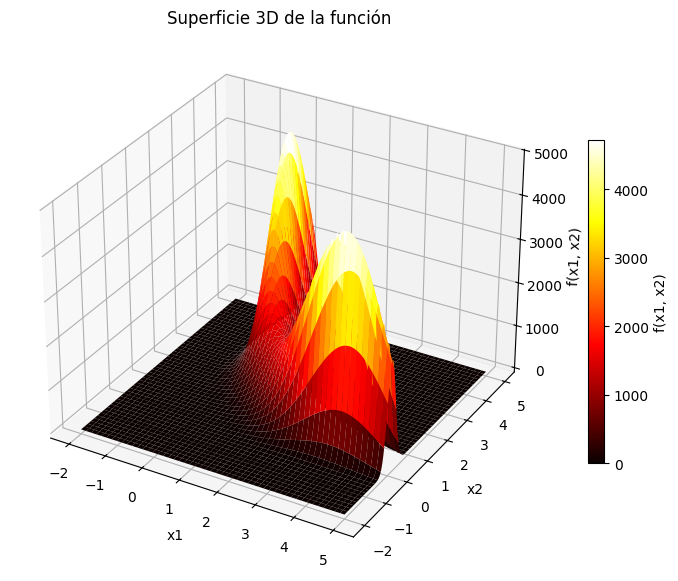

In [30]:
# MALLA PARA GRAFICAR LA FUNCIÓN OBJETIVO

# Definimos los límites del espacio de búsqueda
limites = np.linspace(-2, 5, 300)

# Construimos la cuadrícula bidimensional
A, B = np.meshgrid(limites, limites)

# Evaluamos la función objetivo sobre  la malla
DENSIDAD = np.exp(
    -(A**2 * B**2 + A**2 + B**2 - 8*A - 8*B) / 2
)



# VISUALIZACIÓN: MAPA DE CALOR

fig, ax = plt.subplots(figsize=(10, 8))

mapa = ax.contourf(
    A,
    B,
    DENSIDAD,
    levels=50,
    cmap="hot"
)

cbar = fig.colorbar(mapa, ax=ax)
cbar.set_label("Densidad f(x1, x2)")

ax.set_xlabel("Variable x1")
ax.set_ylabel("Variable x2")
ax.set_title("Mapa de calor de la función objetivo")

plt.tight_layout()
plt.show()

#Gráfica 3D

fig = plt.figure(figsize=(10, 7))

ax = fig.add_subplot(111, projection="3d")

superficie = ax.plot_surface(
    X1,
    X2,
    Z,
    cmap="hot",
    edgecolor="none"
)

fig.colorbar(
    superficie,
    ax=ax,
    shrink=0.6,
    label="f(x1, x2)"
)

ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_zlabel("f(x1, x2)")

ax.set_title("Superficie 3D de la función")

plt.show()

# **Muestras generadas por Metropolis-Hastings sobre el mapa de densidad**

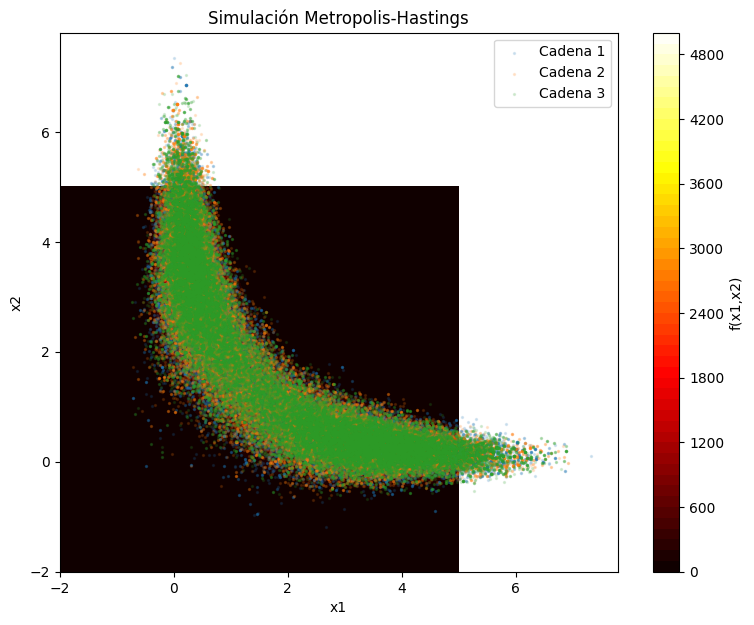

In [24]:
plt.figure(figsize=(9, 7))

# FUNCIÓN OBJETIVO
plt.contourf(
    X1,
    X2,
    Z,
    levels=50,
    cmap="hot"
)

plt.colorbar(label="f(x1,x2)")

# GRÁFICA DE LAS MUESTRAS
for i in range(len(cadenas)):

    plt.scatter(
        cadenas[i][5000:, 0],
        cadenas[i][5000:, 1],
        s=2,
        alpha=0.15,
        label="Cadena " + str(i + 1)
    )

plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Simulación Metropolis-Hastings")
plt.legend()

plt.show()

# **Conclusión**



Se logró implementar exitosamente el algoritmo de Metropolis-Hastings para muestrear la distribución bidimensional definida por la función objetivo. Las gráficas de convergencia evidencian que las tres cadenas, iniciadas en puntos distintos, alcanzan rápidamente un estado estacionario con tasas de aceptación óptimas (≈0.51), demostrando que el tamaño de paso seleccionado permite una exploración eficiente e independiente del punto de partida.

La validación gráfica confirma el cumplimiento del objetivo: la superposición de las muestras sobre el mapa de calor y la superficie 3D revela que los puntos generados se concentran en las regiones de mayor densidad, capturando adecuadamente ambos modos de la distribución.